# Agente inversor: iteración del diseño de la recompensa

Este notebook documenta los pasos 16 a 22 de la actividad:

16. **Primera recompensa**: log-retorno del portafolio, neto de costos
17. **Entrenamiento**: DQN con 3 semillas sobre train (2009–2014)
18. **Observación del comportamiento** en train y en validación (2015)
19. **Identificación de problemas**
20. **Modificación de la recompensa**: penalización por cambiar de posición
21. **Nuevo entrenamiento**, con las mismas semillas e hiperparámetros
22. **Comparación**

**El período de test (2016–2018) no se usa aquí.** Todas las decisiones de este
notebook (incluida la elección de la penalización) se toman con validación,
para que la evaluación final siga siendo sobre datos nunca vistos.

Entrenar los 15 modelos toma ~40 minutos en CPU. Cada modelo y su curva de
aprendizaje se guardan en `saves/`, así que volver a ejecutar el notebook solo
los carga. Para entrenar de nuevo, borre `saves/dqn_investor-*_seed*`.

In [1]:
import os
from pathlib import Path

# Ejecutar desde la raíz del repositorio, como la CLI.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from stable_baselines3 import DQN
from stable_baselines3.common.callbacks import BaseCallback

from rl_games_sb import backtest, config, investor, registry

cfg = config.load("configs/investor_dqn.yaml")
SEEDS = [0, 1, 2]
EVAL_EVERY = 30_000  # pasos entre evaluaciones de la curva de aprendizaje

LABELS = {
    "total_return": "retorno total",
    "annual_return": "retorno anual",
    "volatility": "volatilidad anual",
    "sharpe": "Sharpe",
    "max_drawdown": "drawdown máximo",
    "trades": "operaciones",
    "costs": "costos ($)",
    "exposure": "exposición media",
}
PCT = ["retorno total", "retorno anual", "volatilidad anual", "drawdown máximo"]


def fmt(table):
    # Tabla de métricas con nombres en español y porcentajes legibles.
    table = table.rename(columns=LABELS)
    return table.style.format(
        {c: "{:+.1%}" for c in PCT if c in table}
        | {"Sharpe": "{:.2f}", "operaciones": "{:.0f}", "costos ($)": "{:,.0f}", "exposición media": "{:.2f}"},
        na_rep="—",
    )


print("Hiperparámetros:", cfg.hyperparams)
print(f"Pasos por entrenamiento: {cfg.timesteps:,}")

Hiperparámetros: {'learning_rate': 0.0001, 'buffer_size': 100000, 'learning_starts': 5000, 'batch_size': 64, 'gamma': 0.99, 'train_freq': 4, 'gradient_steps': 1, 'target_update_interval': 1000, 'exploration_fraction': 0.3, 'exploration_final_eps': 0.02, 'policy_kwargs': {'net_arch': [64, 64]}, 'device': 'cpu'}
Pasos por entrenamiento: 300,000


## Baselines de referencia

Antes de mirar al agente, las tres políticas fijas más simples: siempre en
efectivo, siempre 50 % y siempre 100 % (comprar y mantener).

In [2]:
BASELINES = {"efectivo": lambda obs: 0, "siempre 50 %": lambda obs: 1, "comprar y mantener": lambda obs: 2}
PERIODS = ["train", "valid"]

baseline_days = {(p, name): backtest.run(policy, p) for p in PERIODS for name, policy in BASELINES.items()}
baselines = pd.DataFrame({key: backtest.metrics(days) for key, days in baseline_days.items()}).T
baselines = baselines.drop(columns="final_value").rename_axis(["período", "política"])
fmt(baselines)

## 16. Primera recompensa

$$r_t = \ln\left(\frac{V_{t+1}}{V_t}\right)$$

donde $V_t$ es el valor del portafolio al cierre del día $t$, **antes** de
operar, y $V_{t+1}$ es su valor al cierre siguiente, **después** de pagar el
costo de la operación y de que el precio se mueva. Así el costo queda dentro de
la recompensa:

$$V_{t+1} = V_t \,(1 - c\,|w_t - w_{t-1}^{\,\prime}|)\,(1 + w_t R_{t+1})$$

con $c$ = 10 bps, $w_t$ la posición elegida, $w_{t-1}^{\prime}$ la posición
que se traía (después de su deriva) y $R_{t+1}$ el retorno del activo.

**Por qué logarítmico y no el retorno simple:** la suma de las recompensas de un
episodio es exactamente $\ln(V_T / V_0)$, el crecimiento total del capital. El
agente maximiza entonces la riqueza final (crecimiento compuesto), mientras que
la suma de retornos simples no corresponde a ninguna cantidad financiera
(+10 % y luego −10 % suma 0, pero deja el capital en 99 %).

In [3]:
class LearningCurve(BaseCallback):
    # Cada EVAL_EVERY pasos: métricas de la política greedy en train y en validación.

    def __init__(self, env_id, every=EVAL_EVERY):
        super().__init__()
        self.env_id, self.every, self.rows = env_id, every, []

    def _on_step(self):
        if self.n_calls % self.every == 0:
            policy = lambda obs: self.model.predict(obs, deterministic=True)[0]
            row = {"steps": self.num_timesteps}
            for p in PERIODS:
                m = backtest.metrics(backtest.run(policy, p, self.env_id))
                row |= {f"{p}_{k}": m[k] for k in ("total_return", "max_drawdown", "trades", "exposure")}
            self.rows.append(row)
        return True


def train(name, env_id, seed):
    # Entrena (o carga, si ya existe) un DQN con la configuración común y una semilla.
    path = Path("saves") / f"dqn_{name}_seed{seed}.zip"
    curve_path = path.with_suffix(".csv")
    if path.exists() and curve_path.exists():
        return DQN.load(path, device="cpu"), pd.read_csv(curve_path)
    model = registry.create(cfg.algo, env_id, seed=seed, **cfg.hyperparams)
    curve = LearningCurve(env_id)
    model.learn(cfg.timesteps, callback=curve)
    path.parent.mkdir(exist_ok=True)
    model.save(path)
    pd.DataFrame(curve.rows).to_csv(curve_path, index=False)
    return model, pd.DataFrame(curve.rows)


def greedy(model):
    return lambda obs: model.predict(obs, deterministic=True)[0]


def evaluate(models, env_id):
    # Métricas de cada semilla en train y validación, más el detalle diario.
    rows, days = {}, {}
    for seed, model in models.items():
        for p in PERIODS:
            days[(p, seed)] = backtest.run(greedy(model), p, env_id)
            rows[(p, seed)] = backtest.metrics(days[(p, seed)])
    table = pd.DataFrame(rows).T.drop(columns="final_value").rename_axis(["período", "semilla"])
    return table, days

## 17. Entrenamiento con la primera recompensa

Configuración común para todo el notebook: `configs/investor_dqn.yaml`
(300.000 pasos, unas 220 pasadas por los 1.363 días de train), con 3 semillas.
Una sola semilla no basta en RL: el resultado puede cambiar mucho entre
corridas idénticas salvo por la inicialización aleatoria.

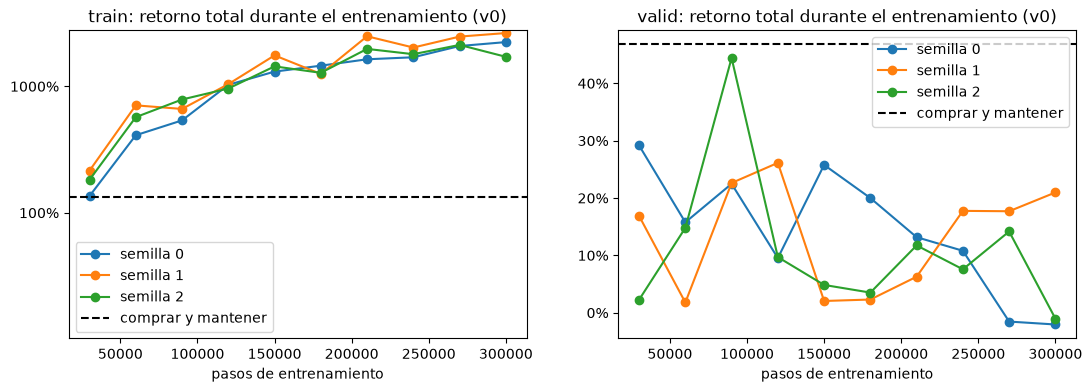

In [4]:
v0 = {seed: train("investor-v0", "investor-v0", seed) for seed in SEEDS}
v0_models = {seed: model for seed, (model, _) in v0.items()}
v0_curves = {seed: curve for seed, (_, curve) in v0.items()}

bh = {p: baselines.loc[(p, "comprar y mantener"), "total_return"] for p in PERIODS}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, p in zip(axes, PERIODS):
    for seed, curve in v0_curves.items():
        ax.plot(curve.steps, curve[f"{p}_total_return"], marker="o", label=f"semilla {seed}")
    ax.axhline(bh[p], color="black", ls="--", label="comprar y mantener")
    ax.set_title(f"{p}: retorno total durante el entrenamiento (v0)")
    ax.set_xlabel("pasos de entrenamiento")
    ax.legend()
axes[0].set_yscale("symlog", linthresh=1)  # train llega a +2.000 %: escala logarítmica
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.show()

## 18. Observación del comportamiento

In [5]:
v0_table, v0_days = evaluate(v0_models, "investor-v0")
fmt(v0_table)

,,retorno total,retorno anual,volatilidad anual,Sharpe,drawdown máximo,operaciones,costos ($),exposición media
período,semilla,,,,,,,,
train,0,+2145.3%,+77.8%,+16.9%,3.48,-11.2%,582,"388,810",0.45
valid,0,-3.1%,-3.1%,+14.1%,-0.15,-16.7%,138,"9,237",0.48
train,1,+2690.9%,+85.1%,+17.8%,3.56,-10.6%,523,"337,690",0.53
valid,1,+20.6%,+20.6%,+22.2%,0.95,-11.3%,118,"11,098",0.52
train,2,+1913.5%,+74.2%,+15.8%,3.58,-5.0%,543,"289,043",0.39
valid,2,+3.8%,+3.9%,+16.3%,0.31,-13.7%,112,"7,320",0.41


In [6]:
def holding_days(days):
    # Duración (en días) de cada tramo con la misma posición objetivo.
    pos = days["position"].dropna()
    return pos.groupby((pos != pos.shift()).cumsum()).size()


behavior = pd.DataFrame({
    (p, seed): {
        "días en 0 %": (d["position"] == 0).mean(),
        "días en 50 %": (d["position"] == 0.5).mean(),
        "días en 100 %": (d["position"] == 1).mean(),
        "días por posición (mediana)": holding_days(d).median(),
        "operaciones por año": backtest.metrics(d)["trades"] / (len(d) / 252),
    }
    for (p, seed), d in v0_days.items()
}).T.rename_axis(["período", "semilla"])
behavior.style.format({c: "{:.0%}" for c in behavior.columns[:3]} | {behavior.columns[3]: "{:.0f}", behavior.columns[4]: "{:.0f}"})

,,días en 0 %,días en 50 %,días en 100 %,días por posición (mediana),operaciones por año
período,semilla,,,,,
train,0,46%,17%,37%,1,108
valid,0,42%,19%,38%,1,138
train,1,38%,18%,44%,2,97
valid,1,43%,10%,46%,1,118
train,2,51%,18%,30%,1,100
valid,2,48%,23%,29%,1,112


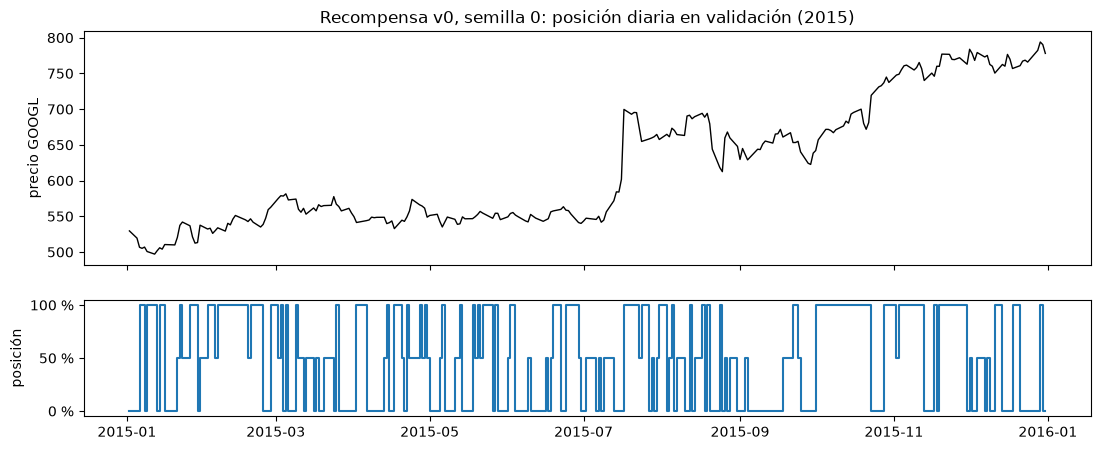

In [7]:
def plot_positions(days, title):
    _, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 5), sharex=True, height_ratios=[2, 1])
    prices = investor.load()["close"].reindex(days.index)
    ax1.plot(prices, color="black", lw=1)
    ax1.set_ylabel("precio GOOGL")
    ax1.set_title(title)
    ax2.step(days.index, days["position"], where="post", color="tab:blue")
    ax2.set_yticks([0, 0.5, 1], ["0 %", "50 %", "100 %"])
    ax2.set_ylabel("posición")
    plt.show()


plot_positions(v0_days[("valid", 0)], "Recompensa v0, semilla 0: posición diaria en validación (2015)")

**Prueba de memorización.** Si el agente aprendió reglas generales (por
ejemplo, "salir cuando la volatilidad sube"), un ruido pequeño en sus
observaciones casi no debería cambiar su resultado. Si en cambio memorizó el
camino de precios de train, reconoce cada día por el valor exacto de sus
indicadores, y un ruido pequeño lo desorienta. Se suma a los cinco indicadores
normalizados un ruido gaussiano de desviación 0,1 (una décima de su desviación
típica en train) y se repite la evaluación en train.

In [8]:
def noisy(model, scale, rng):
    def policy(obs):
        obs = obs.copy()
        obs[:-1] += rng.normal(0, scale, size=len(obs) - 1).astype(np.float32)  # la posición no se toca
        return model.predict(obs, deterministic=True)[0]
    return policy


def memorization_test(models, env_id, scale=0.1, repeats=5):
    rows = {}
    for seed, model in models.items():
        rng = np.random.default_rng(seed)
        clean = backtest.metrics(backtest.run(greedy(model), "train", env_id))["total_return"]
        with_noise = [backtest.metrics(backtest.run(noisy(model, scale, rng), "train", env_id))["total_return"]
                      for _ in range(repeats)]
        rows[seed] = {"train sin ruido": clean, "train con ruido (media de 5)": np.mean(with_noise)}
    return pd.DataFrame(rows).T.rename_axis("semilla")


memo_v0 = memorization_test(v0_models, "investor-v0")
memo_v0.style.format("{:+.0%}")

,train sin ruido,train con ruido (media de 5)
semilla,,
0,+2145%,+1004%
1,+2691%,+1137%
2,+1913%,+822%


## 19. Identificación de problemas

| Problema | Evidencia |
|---|---|
| **Sobreajuste por memorización** | En train gana entre +1.900 % y +2.700 % con Sharpe ~3,5 (comprar y mantener: +134 %). En validación gana −3 %, +21 % y +4 %, contra +47 % de comprar y mantener. En las curvas, train sube sin parar mientras validación no mejora y termina peor que al principio. |
| **Prueba de ruido** | Con un ruido de solo 0,1 desviaciones en las observaciones, el retorno en train cae a menos de la mitad. El agente reconoce cada día por el valor exacto de sus indicadores. |
| **Opera en exceso** | ~100 operaciones por año en train y 112–138 en validación. La mitad de los tramos con una misma posición duran 1 o 2 días. En train pagó ~$340.000 en costos. |
| **Solo busca retornos de corto plazo** | Cambia de posición casi a diario, es decir, intenta adivinar el movimiento del día siguiente, que según el análisis exploratorio no es predecible. |
| **Demasiado tiempo fuera del mercado** | Exposición media de 0,41–0,52 en validación: pasa ~45 % de los días en efectivo en un año que subió +47 %. En el salto de +15 % del 17 de julio, una semilla estaba en 0 % y otra en 50 %. |
| **Riesgo** | Estar fuera la mitad del tiempo no le reduce el riesgo: su drawdown en validación (−11 % a −17 %) es igual o peor que el de comprar y mantener (−12,5 %), con una fracción de su retorno. |

**Por qué ocurre: reward hacking.** La recompensa es financieramente
correcta, porque su suma es el crecimiento del capital. El problema es cómo la
aprovecha el agente. Durante el entrenamiento ve el mismo camino de precios
~220 veces, y en ese camino la forma más fácil de cobrar recompensa no es
aprender reglas generales, sino recordar qué días sube el precio y moverse
justo antes. La recompensa paga cada día por separado y el costo real (10 bps)
es pequeño frente a un movimiento diario típico (~1,5 %), así que cambiar de
posición casi a diario sale rentable **en train**. El agente maximiza la
recompensa, pero con un comportamiento que solo funciona en los datos que
memorizó.

## 20. Modificación de la recompensa

$$r_t = \ln\left(\frac{V_{t+1}}{V_t}\right) - \kappa\,|w_t - w_{t-1}^{\,\prime}|$$

Se resta una penalización $\kappa$ por cada unidad de posición que se cambia,
**además** del costo real de 10 bps, que sigue dentro de $V_{t+1}$. La
penalización solo existe en la recompensa: el valor del portafolio, y por lo
tanto todas las métricas financieras, pagan solo el costo real.

**Por qué esta modificación:** para memorizar el ruido diario, el agente
necesita cambiar de posición muy seguido. Con $\kappa$ alto, un cambio solo
vale la pena si la ganancia esperada se sostiene varios días, que es el tipo
de señal (tendencia, régimen de volatilidad) que el análisis exploratorio
encontró en los datos. Es equivalente a entrenar con costos más altos que los
reales, una forma de regularización.

**Elección de $\kappa$:** se prueban 50, 100, 200, 400 y 800 bps con las mismas 3
semillas e hiperparámetros, y se elige el valor con mejor crecimiento medio
(promedio de ln(V_T / V_0) entre semillas) en **validación**. La grilla empezó
en 50–400; como el mejor valor quedó en el borde (400), se agregó 800 para
comprobar que el óptimo no estaba más allá.

In [9]:
KAPPAS = [50, 100, 200, 400, 800]
for bps in KAPPAS:
    gym.register(f"investor-pen{bps}", entry_point="rl_games_sb.investor:InvestorEnv",
                 kwargs={"trade_penalty_bps": bps})

sweep = {}
for bps in [0, *KAPPAS]:
    env_id = "investor-v0" if bps == 0 else f"investor-pen{bps}"
    models = v0_models if bps == 0 else {s: train(env_id, env_id, s)[0] for s in SEEDS}
    table, _ = evaluate(models, env_id)
    sweep[bps] = table

summary = pd.DataFrame({
    bps: {
        "valid: crecimiento medio": np.log1p(t.loc["valid", "total_return"]).mean(),
        "valid: retorno total medio": t.loc["valid", "total_return"].mean(),
        "valid: retorno peor semilla": t.loc["valid", "total_return"].min(),
        "valid: drawdown medio": t.loc["valid", "max_drawdown"].mean(),
        "valid: operaciones medias": t.loc["valid", "trades"].mean(),
        "train: retorno total medio": t.loc["train", "total_return"].mean(),
    }
    for bps, t in sweep.items()
}).T.rename_axis("κ (bps)")
best_bps = int(summary.drop(index=0)["valid: crecimiento medio"].idxmax())
print(f"κ elegido en validación: {best_bps} bps")
summary.style.format(
    {c: "{:+.1%}" for c in summary.columns}
    | {"valid: operaciones medias": "{:.0f}", "valid: crecimiento medio": "{:+.3f}"}
)

κ elegido en validación: 400 bps


,valid: crecimiento medio,valid: retorno total medio,valid: retorno peor semilla,valid: drawdown medio,valid: operaciones medias,train: retorno total medio
κ (bps),,,,,,
0,+0.064,+7.1%,-3.1%,-13.9%,123,+2249.9%
50,+0.163,+18.3%,+4.8%,-8.3%,64,+1836.3%
100,+0.130,+14.7%,-4.3%,-10.8%,54,+1317.6%
200,+0.204,+22.9%,+12.7%,-15.3%,31,+973.5%
400,+0.442,+56.2%,+39.3%,-9.6%,12,+354.6%
800,+0.361,+43.8%,+29.2%,-9.7%,5,+144.3%


## 21. Nuevo entrenamiento

La versión elegida queda registrada como el entorno `investor-penalized-v0`
(`configs/investor_dqn_penalized.yaml`). Sus modelos son los del barrido con el
$\kappa$ elegido: mismas semillas e hiperparámetros que v0, así que la única
diferencia es la recompensa.

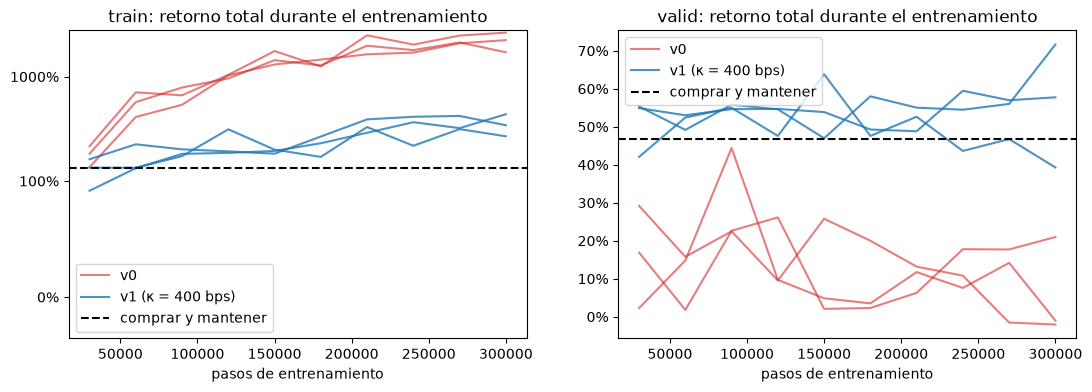

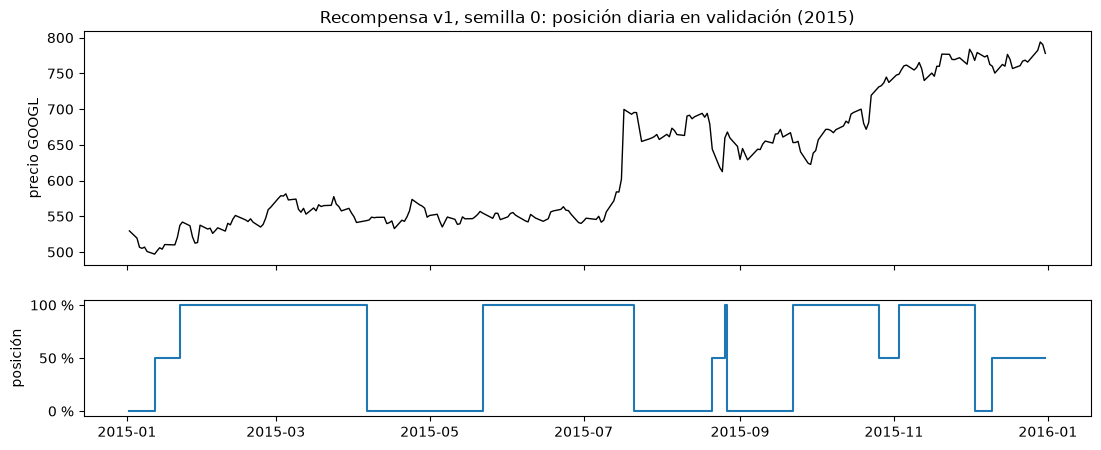

In [10]:
assert gym.spec("investor-penalized-v0").kwargs["trade_penalty_bps"] == best_bps, "el entorno no usa el κ elegido"

v1 = {s: train(f"investor-pen{best_bps}", f"investor-pen{best_bps}", s) for s in SEEDS}
v1_models = {seed: model for seed, (model, _) in v1.items()}
v1_curves = {seed: curve for seed, (_, curve) in v1.items()}
v1_table, v1_days = evaluate(v1_models, "investor-penalized-v0")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, p in zip(axes, PERIODS):
    for seed in SEEDS:
        ax.plot(v0_curves[seed].steps, v0_curves[seed][f"{p}_total_return"], color="tab:red", alpha=0.6,
                label="v0" if seed == 0 else None)
        ax.plot(v1_curves[seed].steps, v1_curves[seed][f"{p}_total_return"], color="tab:blue", alpha=0.8,
                label=f"v1 (κ = {best_bps} bps)" if seed == 0 else None)
    ax.axhline(bh[p], color="black", ls="--", label="comprar y mantener")
    ax.set_title(f"{p}: retorno total durante el entrenamiento")
    ax.set_xlabel("pasos de entrenamiento")
    ax.legend()
axes[0].set_yscale("symlog", linthresh=1)
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.show()

plot_positions(v1_days[("valid", 0)], "Recompensa v1, semilla 0: posición diaria en validación (2015)")

## 22. Comparación

In [11]:
rows = []
for name, table in [("v0", v0_table), (f"v1 (κ = {best_bps} bps)", v1_table)]:
    for p in PERIODS:
        t = table.loc[p]
        rows.append({"período": p, "política": f"{name}, media de 3 semillas", **t.mean().to_dict()})
        rows.append({"período": p, "política": f"{name}, peor semilla", **t.loc[t["total_return"].idxmin()].to_dict()})
for (p, name), m in baselines.iterrows():
    rows.append({"período": p, "política": name, **m.to_dict()})

comparison = pd.DataFrame(rows).set_index(["período", "política"]).sort_index(level=0, sort_remaining=False)
fmt(comparison[[c for c in LABELS if c in comparison]])

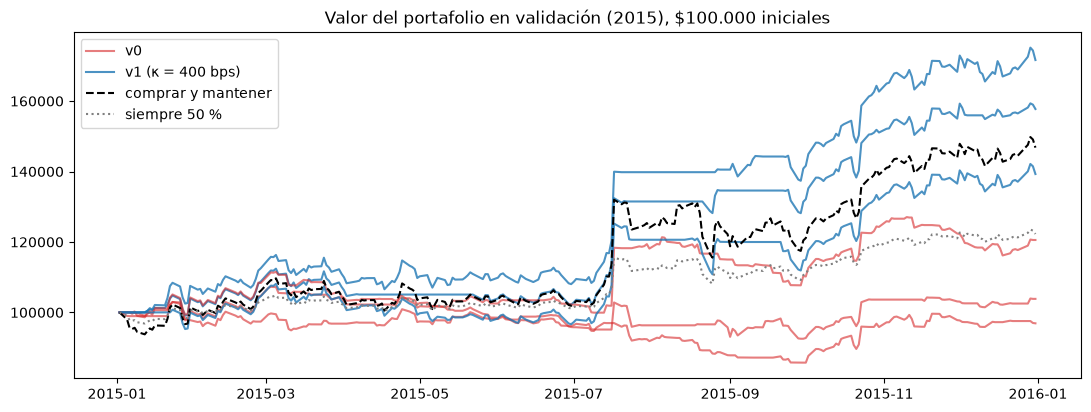

In [12]:
fig, ax = plt.subplots(figsize=(13, 4.5))
for seed in SEEDS:
    ax.plot(v0_days[("valid", seed)]["value"], color="tab:red", alpha=0.6, label="v0" if seed == 0 else None)
    ax.plot(v1_days[("valid", seed)]["value"], color="tab:blue", alpha=0.8,
            label=f"v1 (κ = {best_bps} bps)" if seed == 0 else None)
ax.plot(baseline_days[("valid", "comprar y mantener")]["value"], color="black", ls="--", label="comprar y mantener")
ax.plot(baseline_days[("valid", "siempre 50 %")]["value"], color="gray", ls=":", label="siempre 50 %")
ax.set_title("Valor del portafolio en validación (2015), $100.000 iniciales")
ax.legend()
plt.show()

memo_v1 = memorization_test(v1_models, "investor-penalized-v0")
pd.concat({"v0": memo_v0, f"v1 (κ = {best_bps} bps)": memo_v1}).style.format("{:+.0%}")

### Conclusiones de la iteración

| | v0 | v1 (κ = 400 bps) | comprar y mantener |
|---|---|---|---|
| Retorno en validación (media de 3 semillas) | +7 % | **+56 %** | +47 % |
| Peor semilla en validación | −3 % | +39 % | — |
| Drawdown máximo en validación | −14 % | **−10 %** | −12,5 % |
| Sharpe en validación | 0,37 | **1,91** | 1,47 |
| Operaciones en validación | 123 | 12 | 1 |
| Costos en validación | $9.200 | $980 | $100 |
| Retorno en train | +2.250 % | +355 % | +134 % |

1. **El exceso de operaciones se corrige.** Las operaciones bajan de ~123 a
   ~12 al año y los costos caen a la décima parte. El agente mantiene cada
   posición semanas o meses.
2. **La generalización mejora mucho.** La peor semilla de v1 (+39 %) supera a
   la mejor de v0 (+21 %). La brecha entre train y validación se reduce, y el
   ruido en las observaciones ya casi no cambia su resultado en train: dejó de
   depender de recordar días exactos.
3. **Menos riesgo que comprar y mantener en validación:** menor drawdown y
   mayor Sharpe, con una exposición media de 0,73.

**Cautelas, importantes para el informe:**

- **Sesgo de selección.** κ se eligió mirando validación entre cinco
  valores, así que el resultado en validación es optimista. Solo el período
  de test, que no se ha usado, dirá si la mejora es real.
- **Un año, pocas decisiones.** Validación es un solo año, y buena parte de
  la ventaja de v1 se decide en pocos días: las 3 semillas estaban al 100 % en
  el salto de +15 % del 17 de julio, y dos de ellas estaban casi fuera durante
  la caída de agosto. Con otra secuencia de eventos el resultado podría ser
  distinto.
- **Queda algo de sobreajuste.** v1 todavía gana en train casi tres veces lo
  de comprar y mantener. Con κ = 800 eso desaparece, pero también empeora en
  validación: más penalización acerca al agente a no operar nunca.
- **Más penalización empuja hacia comprar y mantener.** El agente aprende a
  estar invertido la mayor parte del tiempo y salir solo en episodios
  puntuales. Es una estrategia más sensata, pero hay que comprobar en test que
  sus salidas aportan algo frente a simplemente quedarse invertido.